In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df =pd.read_csv("powerplant_data.csv")

In [ ]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


AT->Temperature

V->Vaccum

AP->Pressure

RH->Humidity

PE->Produced Energy

In [ ]:
df.isnull().sum()

,0
AT,0
V,0
AP,0
RH,0
PE,0


In [ ]:
X= df.drop("PE",axis=1)
y= df["PE"]

In [ ]:
X.head()


,AT,V,AP,RH
0,8.34,40.77,1010.84,90.01
1,23.64,58.49,1011.40,74.20
2,29.74,56.90,1007.15,41.91
3,19.07,49.69,1007.22,76.79
4,11.80,40.66,1017.13,97.20


In [ ]:
y.head()

,PE
0,480.48
1,445.75
2,438.76
3,453.09
4,464.43


Step-2: Standardize

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Step 3-> Convert to tensors

In [ ]:
import torch
import torch.nn as nn


In [ ]:
X_train_tensor = torch.tensor(X_train_scaled,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled,dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_test_tensor = torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

Step 4-> Tensor Dataset and DataLoader

In [ ]:
from torch.utils.data import TensorDataset,DataLoader

In [ ]:
train_dataset= TensorDataset(X_train_tensor,y_train_tensor)
test_dataset= TensorDataset(X_test_tensor,y_test_tensor)

In [ ]:
train_loader= DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader= DataLoader(test_dataset,batch_size=32)

ANN

In [ ]:
class ANN(nn.Module):
  def __init__(self):
    super(ANN,self).__init__()

    self.model=nn.Sequential(
        nn.Linear(4,6),
        nn.ReLU(),
        nn.Linear(6,6),
        nn.ReLU(),
        nn.Linear(6,1)
    )

  def forward(self,x):
    return self.model(x)

In [ ]:
import torch.optim as optim
model = ANN()
criterian = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [ ]:
# Train the ANN
train_losses = []
val_losses = []

best_val_loss = float("inf")

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0  # tot training loss for 1 epoch

    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch

        optimizer.zero_grad()

        outputs = model(xb)  # forward prop....predicted outputs for this batch
        loss = criterian(outputs, yb)  # compute loss
        loss.backward()  # back prop.. compute gradients
        optimizer.step()  # params update

        running_loss += loss.item()  # loss is a tensor => py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)
    model.eval()
    # Validation
    running_val_loss = 0.0

    with torch.no_grad():  # no gradients compute
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = criterian(outputs, yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt")  # .pt or .pth

epoch 1/100 ==> train loss = 206506.59921875 & val loss = 205456.953125
epoch 2/100 ==> train loss = 201913.657421875 & val loss = 195215.953125
epoch 3/100 ==> train loss = 179566.53678385416 & val loss = 158197.859375
epoch 4/100 ==> train loss = 129619.5509765625 & val loss = 100475.2421875
epoch 5/100 ==> train loss = 75029.38422851563 & val loss = 54126.98828125
epoch 6/100 ==> train loss = 41083.19390462239 & val loss = 31575.822265625
epoch 7/100 ==> train loss = 26221.878186035156 & val loss = 21995.951171875
epoch 8/100 ==> train loss = 19570.565991210937 & val loss = 17321.15234375
epoch 9/100 ==> train loss = 15896.016617838543 & val loss = 14153.84375
epoch 10/100 ==> train loss = 12885.64614461263 & val loss = 11274.9208984375
epoch 11/100 ==> train loss = 10089.66421508789 & val loss = 8556.59375
epoch 12/100 ==> train loss = 7522.261844889323 & val loss = 6227.9970703125
epoch 13/100 ==> train loss = 5418.229787699382 & val loss = 4412.31982421875
epoch 14/100 ==> train 

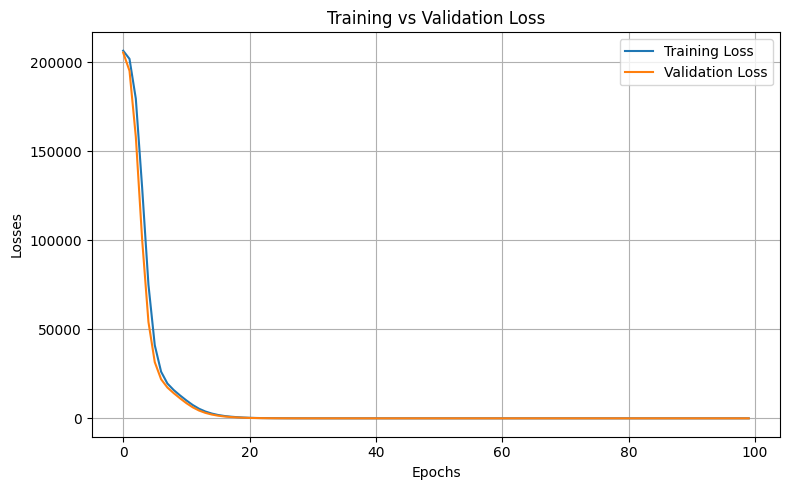

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.figure(figsize=(8, 5))

plt.plot(loss_df["Training Loss"], label="Training Loss")
plt.plot(loss_df["Validation Loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.title("Training vs Validation Loss")
plt.legend()

plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
# Loading the best model

model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [ ]:
# Evaluation

model.eval()

with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterian(train_preds, y_train_tensor)
    test_mse_loss = criterian(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 20.505043029785156
Testing MSE: 18.767757415771484


In [ ]:
from sklearn.metrics import r2_score

print("r^2 score =", r2_score(y_test, test_preds))

r^2 score = 0.9344115296055421


In [ ]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.079865,433.27
1,436.935638,438.16
2,461.365356,458.42
3,476.439056,480.82
4,435.173706,441.41
...,...,...
1909,451.394196,456.70
1910,431.556763,438.04
1911,467.473022,467.80
1912,430.999695,437.14
